L'OBJECTIF EST D'AGREGER LES DONNEES DES APL 

1-Importation, visualisation et nettoyage

In [21]:
%pip install python-calamine

     -------------------------------------- 692.6/692.6 kB 2.6 MB/s eta 0:00:00
     -------------------------------------- 130.0/130.0 kB 2.5 MB/s eta 0:00:00
  Attempting uninstall: packaging
    Found existing installation: packaging 21.3
    Uninstalling packaging-21.3:
      Successfully uninstalled packaging-21.3
Note: you may need to restart the kernel to use updated packages.


ERROR: pip's dependency resolver does not currently take into account all the packages that are installed. This behaviour is the source of the following dependency conflicts.
streamlit 1.46.1 requires packaging<26,>=20, but you have packaging 26.3 which is incompatible.


In [ ]:
import os
import requests
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt

Pour favoriser la reproductibilité, nous feront en sorte que les données puissent être téléchargées en ligne

In [3]:
def telecharger(url, chemin):
    """Télécharge url et l'enregistre dans chemin (sans retélécharger si le fichier existe)."""
    if os.path.exists(chemin):
        return
    os.makedirs(os.path.dirname(chemin), exist_ok=True)
    reponse = requests.get(url, timeout=60)
    reponse.raise_for_status()                 # erreur claire si le lien est mort
    with open(chemin, "wb") as f:
        f.write(reponse.content)

URL_APL = "https://data.drees.solidarites-sante.gouv.fr/api/datasets/1.0/530_l-accessibilite-potentielle-localisee-apl/attachments/indicateur_d_apl_aux_medecins_generalistes_xlsx/"
telecharger(URL_APL, "data/raw/apl.xlsx")

# Contrôle : on doit voir les feuilles Paramètres, APL 2022, APL 2023, APL 2024
print(pd.ExcelFile("data/raw/apl.xlsx").sheet_names)

['Paramètres', 'APL 2022', 'APL 2023', 'APL 2024']


In [ ]:
# Lecture de la feuille APL 2024 : on saute les 8 lignes de titre, la ligne 9 devient l'en-tête
apl = pd.read_excel("data/raw/apl.xlsx", sheet_name="APL 2024", skiprows=8, dtype=str)

# La première ligne lue est la ligne d'unités : on la supprime
apl = apl.iloc[1:]


#visualisation de la base 
apl.head(3)                 

,Code commune INSEE,Commune,APL aux médecins généralistes,APL aux médecins généralistes de 65 ans ou moins,APL aux médecins généralistes de 62 ans ou moins,APL aux médecins généralistes de 60 ans ou moins,Population standardisée 2022 pour la médecine générale,Population totale 2022
1,01001,L'Abergement-Clémenciat,1.953,1.789,1.513,1.259,864.967,859
2,01002,L'Abergement-de-Varey,2.211,1.767,1.345,1.345,264.671,273
3,01004,Ambérieu-en-Bugey,3.098,2.52,2.029,1.907,15282.591,15553.99999999999


In [9]:
#renommage des colonnes 
# ---------- Noms courts ----------
apl.columns = ["codgeo", "commune", "apl", "apl65", "apl62", "apl60",
               "pop_std", "pop_tot"]

In [10]:
print(apl.dtypes)

codgeo     object
commune    object
apl        object
apl65      object
apl62      object
apl60      object
pop_std    object
pop_tot    object
dtype: object


In [11]:
#transformation en numérique
apl[["apl", "apl65", "apl62", "apl60", "pop_std", "pop_tot"]] = apl[["apl", "apl65", "apl62", "apl60", "pop_std", "pop_tot"]].apply(pd.to_numeric)

In [12]:
#valeurs manquantes
apl.isna().sum()

codgeo     0
commune    0
apl        0
apl65      0
apl62      0
apl60      0
pop_std    0
pop_tot    0
dtype: int64

2-Début de fusion entre la base des apl et celle contenant la repartition géographique de l'INSEE

In [13]:
#importation de la base contenant les communes, régions et départements
geo = pd.read_excel("rattachements_com_dep_arr.xlsx", dtype=str)

In [14]:
len(geo)

34875

In [15]:
len(apl)

34890

In [ ]:
def codes_absents(apl, geo):
    codes_geo = set(geo["CODGEO"])
    absents = []
    for code in apl["codgeo"]:
        if code not in codes_geo:
            absents.append(code)

    print("Nombre de codes absents :", len(absents))

    for code in absents:
        ligne = apl[apl["codgeo"] == code]
        print(code, ligne["commune"].values[0], round(ligne["pop_tot"].values[0]))

    return absents

In [26]:
codes_absents(apl, geo)

Nombre de codes absents : 45
13201 Marseille 1er Arrondissement 38482
13202 Marseille 2e Arrondissement 24153
13203 Marseille 3e Arrondissement 55653
13204 Marseille 4e Arrondissement 49744
13205 Marseille 5e Arrondissement 45020
13206 Marseille 6e Arrondissement 38804
13207 Marseille 7e Arrondissement 34866
13208 Marseille 8e Arrondissement 83414
13209 Marseille 9e Arrondissement 76347
13210 Marseille 10e Arrondissement 59852
13211 Marseille 11e Arrondissement 59033
13212 Marseille 12e Arrondissement 64276
13213 Marseille 13e Arrondissement 93425
13214 Marseille 14e Arrondissement 59230
13215 Marseille 15e Arrondissement 79501
13216 Marseille 16e Arrondissement 15415
69381 Lyon 1er Arrondissement 29040
69382 Lyon 2e Arrondissement 29880
69383 Lyon 3e Arrondissement 101523
69384 Lyon 4e Arrondissement 35232
69385 Lyon 5e Arrondissement 48277
69386 Lyon 6e Arrondissement 50718
69387 Lyon 7e Arrondissement 87491
69388 Lyon 8e Arrondissement 84956
69389 Lyon 9e Arrondissement 53657
75101 

['13201',
 '13202',
 '13203',
 '13204',
 '13205',
 '13206',
 '13207',
 '13208',
 '13209',
 '13210',
 '13211',
 '13212',
 '13213',
 '13214',
 '13215',
 '13216',
 '69381',
 '69382',
 '69383',
 '69384',
 '69385',
 '69386',
 '69387',
 '69388',
 '69389',
 '75101',
 '75102',
 '75103',
 '75104',
 '75105',
 '75106',
 '75107',
 '75108',
 '75109',
 '75110',
 '75111',
 '75112',
 '75113',
 '75114',
 '75115',
 '75116',
 '75117',
 '75118',
 '75119',
 '75120']

Donc 45 codes de la base APL (arrondissements municipaux de Paris, Lyon et Marseille) ne figurent pas dans la table d’appartenance des communes. 

3-Rattachement des codes restants 

Nous possédons la répartition géographique avec les codes régions, les arrondissements, départements et communes correspondants donc nous allons les utiliser. Ces derniers proviennent de l'INSEE 

In [33]:
#les répartitions se sont faits dans deux différents fichiers donc il a fallu faire une concaténation pour obtenir une base de 
#commune complète

fichier = "data/raw/table-appartenance-geo-communes-2025.xlsx"
cols = ["CODGEO", "LIBGEO", "DEP", "REG", "ARR"]

com = pd.read_excel(fichier, sheet_name="COM", header=5, dtype=str, usecols=cols, engine="calamine") 
arm = pd.read_excel(fichier, sheet_name="ARM", header=5, dtype=str, usecols=cols, engine="calamine")

df = pd.concat([com, arm], ignore_index=True) #permet de jetter les anciens indices et d'en créer un autre 

In [34]:
geo2 = df
codes_absents(apl, geo2)

Nombre de codes absents : 0


[]

Nous avons maintenant 0 absents donc nous pouvons faire la fusion et obtenir la base finale

In [35]:
df = pd.merge(left=apl, right=geo2[["CODGEO", "DEP", "REG", "ARR"]],
              left_on="codgeo", right_on="CODGEO", how="left")
df.head()
df.dtypes

codgeo      object
commune     object
apl        float64
apl65      float64
apl62      float64
apl60      float64
pop_std    float64
pop_tot    float64
CODGEO      object
DEP         object
REG         object
ARR         object
dtype: object

In [36]:
print(len(apl), len(df))        
print(df["REG"].isna().sum())  

34890 34890
0


4-Agrégation

In [37]:
def agreger(df, niveau, indicateur="apl"):
    """Cette fonction calcule l'APL moyen pondéré par la population standardisée, par territoire."""
    d = df.copy()
    d["pond"] = d[indicateur] * d["pop_std"]            # APL × population standardisée
    res = d.groupby(niveau)[["pond", "pop_std", "pop_tot"]].sum()
    res[indicateur] = res["pond"] / res["pop_std"]      # somme pondérée / somme des poids
    return res[[indicateur, "pop_std", "pop_tot"]].reset_index()

In [38]:
apl_reg = agreger(df, "REG")
apl_dep = agreger(df, "DEP")
apl_arr = agreger(df, ["DEP", "ARR"])   # DEP + ARR pour que chaque arrondissement soit unique


5-Visualisation de la base et analyse des disparités

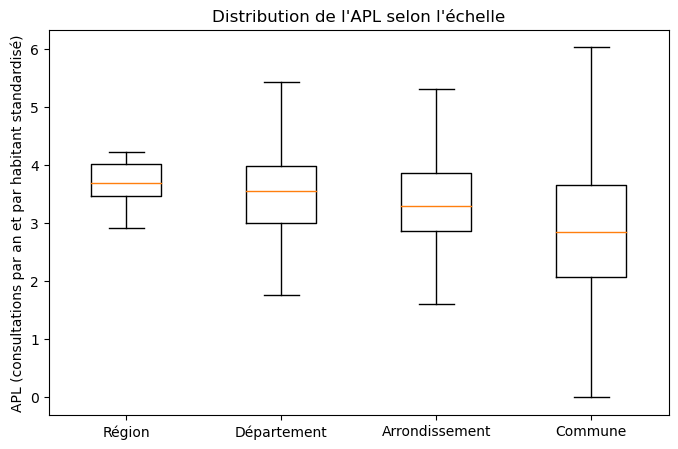

In [ ]:
# Les 4 séries d'APL à comparer
donnees = [apl_reg["apl"], apl_dep["apl"], apl_arr["apl"], df["apl"]]
noms = ["Région", "Département", "Arrondissement", "Commune"]

plt.figure(figsize=(8, 5))
plt.boxplot(donnees, labels=noms, showfliers=False)   # showfliers=False : on masque les valeurs extrêmes
plt.ylabel("APL (consultations par an et par habitant standardisé)")
plt.title("Distribution de l'APL selon l'échelle")
plt.show()

Ce graphique laisse apparaitre des inégalités locales. On se rend compte que la dispersion aux échelles plus grande est moins prononcée que lorsqu'on analyse en profondeur. Donc le phénomène d'accès aux medecins devrait être étudié à différentes échelles pour percevoir les disparités

In [40]:
seuil = 2.5

sous = df[df["apl"] <= seuil].groupby("DEP")["pop_tot"].sum()   # habitants dans une commune sous le seuil
tot = df.groupby("DEP")["pop_tot"].sum()                        # habitants du département
part_dep = (sous / tot).fillna(0).sort_values(ascending=False)

print(part_dep.head(10).round(3))   # les 10 départements les plus touchés

DEP
95     0.691
973    0.684
91     0.644
77     0.609
28     0.593
18     0.578
78     0.539
01     0.522
89     0.508
48     0.490
Name: pop_tot, dtype: float64


Dans le département 95, 69.1% des habitants vivent dans une commune où l’APL est inférieur ou égal à 2,5 consultations par an et par habitant. Ces habitants ont donc, en moyenne, un accès faible aux médecins généralistes selon le critère de la DREES. L'interpretation reste la même pour les autres départements.

   REG                         nom   apl     pop_tot
2   03                      Guyane  1.76    288382.0
5   24         Centre-Val de Loire  2.91   2581597.0
4   11               Île-de-France  3.35  12380964.0
6   27     Bourgogne-Franche-Comté  3.43   2803977.0
10  52            Pays de la Loire  3.47   3879216.0
7   28                   Normandie  3.49   3339074.0
14  84        Auvergne-Rhône-Alpes  3.56   8163884.0
0   01                  Guadeloupe  3.57    383569.0
1   02                  Martinique  3.70    361019.0
13  76                   Occitanie  3.84   6080731.0
16  94                       Corse  3.90    351276.0
9   44                   Grand Est  3.95   5560079.0
12  75          Nouvelle-Aquitaine  4.02   6113384.0
11  53                    Bretagne  4.02   3422845.0
8   32             Hauts-de-France  4.05   5998916.0
15  93  Provence-Alpes-Côte d'Azur  4.23   5170312.0
3   04                  La Réunion  5.44    881348.0


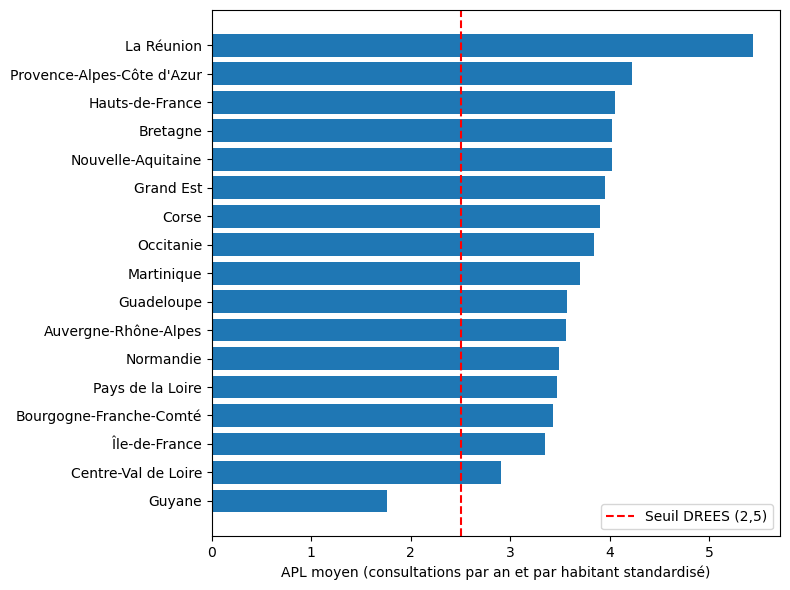

In [41]:
noms_reg = {"01": "Guadeloupe", "02": "Martinique", "03": "Guyane", "04": "La Réunion",
            "11": "Île-de-France", "24": "Centre-Val de Loire", "27": "Bourgogne-Franche-Comté",
            "28": "Normandie", "32": "Hauts-de-France", "44": "Grand Est", "52": "Pays de la Loire",
            "53": "Bretagne", "75": "Nouvelle-Aquitaine", "76": "Occitanie",
            "84": "Auvergne-Rhône-Alpes", "93": "Provence-Alpes-Côte d'Azur", "94": "Corse"}

apl_reg["nom"] = apl_reg["REG"].map(noms_reg)
apl_reg = apl_reg.sort_values("apl")
print(apl_reg[["REG", "nom", "apl", "pop_tot"]].round(2))


import matplotlib.pyplot as plt

plt.figure(figsize=(8, 6))
plt.barh(apl_reg["nom"], apl_reg["apl"])
plt.axvline(2.5, color="red", linestyle="--", label="Seuil DREES (2,5)")
plt.xlabel("APL moyen (consultations par an et par habitant standardisé)")
plt.legend()
plt.tight_layout()
plt.show()

Les régions sont proches, de 2,91 (Centre-Val de Loire) à près de 6 (La Reunion). Seule la Guyane (1,76) est nettement en dessous du seuil de 2,5, et toutes les autres régions sont au-dessus. Cela montre que l’échelle régionale cache les inégalités locales, comme on l’a vu avec la part de population sous le seuil par département.

In [42]:
apl_dep = agreger(df, "DEP")

print(apl_dep.sort_values("apl").head(10).round(2))   # les 10 moins bien dotés
print(apl_dep.sort_values("apl").tail(10).round(2))   # les 10 mieux dotés

    DEP   apl     pop_std    pop_tot
98  973  1.76   257507.45   288382.0
17   18  2.26   312110.82   299496.0
77   77  2.31  1397535.69  1452399.0
26   28  2.36   435246.10   432950.0
95   95  2.37  1214268.75  1270845.0
91   91  2.39  1281122.97  1324546.0
78   78  2.47  1434538.31  1470778.0
89   89  2.52   344684.13   333896.0
25   27  2.55   598640.45   601305.0
48   48  2.56    79655.31    76503.0
    DEP   apl     pop_std    pop_tot
5    06  4.46  1153062.38  1114579.0
80   80  4.47   563658.59   565540.0
59   59  4.50  2550371.99  2616909.0
64   64  4.57   722945.83   699473.0
12   13  4.60  2076180.99  2069811.0
33   33  4.80  1661885.39  1674980.0
4    05  4.81   147426.80   141677.0
67   67  4.91  1145272.70  1156963.0
99  974  5.44   834784.56   881348.0
75   75  5.50  2062654.29  2113705.0
